# Forecasting utility-billed water demand in Oka Community, Benin City

This notebook reproduces every number and figure in the manuscript *Neural network versus regression models for forecasting utility-billed water demand in a data-scarce urban community: a case study of Oka, Benin City, Nigeria* (Ulokaji and Bobor).

**Question.** With 11 annual observations, does an artificial neural network (ANN) forecast billed water demand better than simple regression?

**Answer in this data set.** No. Linear regression on population is the most accurate model under both validation schemes, and rainfall, temperature and humidity add no skill.

**How to run.** Run the cells from top to bottom. Python 3.9 or newer with `numpy`, `scipy`, `scikit-learn` and `matplotlib` is enough. The whole notebook takes about two minutes. The last cell checks that the key results match the values reported in the paper.

**Data.** Annual population and utility-billed demand come from the Edo State Urban Water Corporation (EDUWC). Climate data: see the note under the data table.

In [1]:
import warnings, itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e3e0", "axes.axisbelow": True})
BLUE, ORANGE = "#2a6fb0", "#c4691a"

## 1. Data

Eleven annual records, 2014 to 2024. The EDUWC annual supply figure was 525,600,000 L in every year, so it carries no information about year-to-year change and is left out of all models.

> **Climate data source:** replace this line with the station or product name and access date before publishing.

In [2]:
year = np.arange(2014, 2025)
pop  = np.array([8362, 8654, 8955, 9269, 9594, 9930, 10278, 10637, 11010, 11395, 11794], float)
dem  = np.array([4321823, 4821773, 4859111, 5133422, 5579056, 6232825, 6047859, 6908741, 7486717, 7172411, 8157287], float)
rain = np.array([1842, 2161, 1816, 1990, 1871, 2001, 1947, 2024, 2109, 2120, 1864], float)
temp = np.array([32.2, 30.5, 28.4, 28.5, 25.5, 33.0, 30.7, 33.4, 31.7, 27.0, 28.7])
hum  = np.array([75.3, 79.9, 75.2, 70.8, 88.3, 74.9, 76.4, 79.6, 82.4, 85.2, 85.9])
n = len(year)
X = np.c_[pop, rain, temp, hum]          # column 0 is population, columns 1 to 3 are climate

print(f"{'Year':>5} {'Population':>11} {'Demand (L/yr)':>14} {'Rain mm':>8} {'Temp C':>7} {'RH %':>6}")
for i in range(n):
    print(f"{year[i]:>5} {pop[i]:>11,.0f} {dem[i]:>14,.0f} {rain[i]:>8,.0f} {temp[i]:>7.1f} {hum[i]:>6.1f}")

 Year  Population  Demand (L/yr)  Rain mm  Temp C   RH %
 2014       8,362      4,321,823    1,842    32.2   75.3
 2015       8,654      4,821,773    2,161    30.5   79.9
 2016       8,955      4,859,111    1,816    28.4   75.2
 2017       9,269      5,133,422    1,990    28.5   70.8
 2018       9,594      5,579,056    1,871    25.5   88.3
 2019       9,930      6,232,825    2,001    33.0   74.9
 2020      10,278      6,047,859    1,947    30.7   76.4
 2021      10,637      6,908,741    2,024    33.4   79.6
 2022      11,010      7,486,717    2,109    31.7   82.4
 2023      11,395      7,172,411    2,120    27.0   85.2
 2024      11,794      8,157,287    1,864    28.7   85.9


## 2. Describing the data

Billed demand is compared with population, and the elasticity of demand to population is estimated from a log-log regression.

In [3]:
pop_cagr = (pop[-1] / pop[0]) ** (1 / (n - 1)) - 1
dem_cagr = (dem[-1] / dem[0]) ** (1 / (n - 1)) - 1
percap = dem / pop / 365                  # litres per person per day
print(f"Population growth: {pop_cagr*100:.1f}% per year   Demand growth: {dem_cagr*100:.1f}% per year")
print(f"Billed use per person: {percap[0]:.2f} L/day in 2014, {percap[-1]:.2f} L/day in 2024")
for name, v in (("population", pop), ("rainfall", rain), ("temperature", temp), ("humidity", hum)):
    print(f"Correlation of demand with {name:<12}: r = {np.corrcoef(dem, v)[0,1]:.2f}")

A = np.c_[np.ones(n), np.log(pop)]
b = np.linalg.lstsq(A, np.log(dem), rcond=None)[0]
res = np.log(dem) - A @ b
cov = (res @ res / (n - 2)) * np.linalg.inv(A.T @ A)
print(f"Elasticity of demand to population: {b[1]:.2f} (standard error {np.sqrt(cov[1,1]):.2f})")

Population growth: 3.5% per year   Demand growth: 6.6% per year
Billed use per person: 1.42 L/day in 2014, 1.89 L/day in 2024
Correlation of demand with population  : r = 0.98
Correlation of demand with rainfall    : r = 0.26
Correlation of demand with temperature : r = 0.02
Correlation of demand with humidity    : r = 0.57
Elasticity of demand to population: 1.78 (standard error 0.10)


## 3. Candidate models

Five specifications are compared: a per-capita ratio, linear regression on population, linear regression on population plus climate, and an ANN on population or on population plus climate. A log-log regression is added as a sensitivity check.

The ANN has one hidden layer of four tanh units, an L2 penalty of 0.01 and the L-BFGS optimiser, on standardised inputs and output. Each prediction is the mean of 25 networks started from different random seeds.

In [4]:
def ols_fit(Xtr, y):
    return np.linalg.lstsq(np.c_[np.ones(len(Xtr)), Xtr], y, rcond=None)[0]

def ols_pred(beta, Xte):
    return np.c_[np.ones(len(Xte)), Xte] @ beta

def ann_predict(Xtr, ytr, Xte, hidden=(4,), alpha=1e-2, activation="tanh", seeds=25):
    sx = StandardScaler().fit(Xtr)
    sy = StandardScaler().fit(ytr.reshape(-1, 1))
    preds = []
    for seed in range(seeds):
        net = MLPRegressor(hidden_layer_sizes=hidden, activation=activation, solver="lbfgs",
                           alpha=alpha, max_iter=2000, random_state=seed)
        net.fit(sx.transform(Xtr), sy.transform(ytr.reshape(-1, 1)).ravel())
        preds.append(sy.inverse_transform(net.predict(sx.transform(Xte)).reshape(-1, 1)).ravel())
    return np.mean(preds, axis=0)

def make_model(name):
    if name == "Per-capita ratio":
        return lambda Xtr, ytr, Xte: Xte[:, 0] * np.mean(ytr / Xtr[:, 0])
    if name == "Linear (population)":
        return lambda Xtr, ytr, Xte: ols_pred(ols_fit(Xtr[:, :1], ytr), Xte[:, :1])
    if name == "Linear (population + climate)":
        return lambda Xtr, ytr, Xte: ols_pred(ols_fit(Xtr, ytr), Xte)
    if name == "Log-log (population)":
        def f(Xtr, ytr, Xte):
            bb = np.linalg.lstsq(np.c_[np.ones(len(Xtr)), np.log(Xtr[:, 0])], np.log(ytr), rcond=None)[0]
            return np.exp(bb[0] + bb[1] * np.log(Xte[:, 0]))
        return f
    if name == "ANN (population)":
        return lambda Xtr, ytr, Xte: ann_predict(Xtr[:, :1], ytr, Xte[:, :1])
    if name == "ANN (population + climate)":
        return lambda Xtr, ytr, Xte: ann_predict(Xtr, ytr, Xte)
    raise ValueError(name)

def metrics(y, p):
    e = p - y
    return dict(MAE=np.mean(abs(e)), RMSE=np.sqrt(np.mean(e**2)), MAPE=np.mean(abs(e)/y)*100,
                R2=1 - np.sum(e**2) / np.sum((y - y.mean())**2))

## 4. Out-of-sample validation

Every model is refitted from scratch for each forecast.

* **Leave-one-out (LOO):** predict each year from a model fitted to the other ten.
* **Rolling-origin (RO):** train on 2014 to 2018 and forecast 2019, then add one year at a time, giving six one-step-ahead forecasts for 2019 to 2024.

Errors are in litres per year. R² is computed on the pooled out-of-sample forecasts, so with only six rolling-origin points it should be read with care.

In [5]:
models = ["Per-capita ratio", "Linear (population)", "Linear (population + climate)",
          "Log-log (population)", "ANN (population)", "ANN (population + climate)"]
loo, ro = {}, {}
for m in models:
    f = make_model(m)
    loo_pred = np.array([f(X[np.arange(n) != i], dem[np.arange(n) != i], X[i:i+1])[0] for i in range(n)])
    ro_pred  = np.array([f(X[:k], dem[:k], X[k:k+1])[0] for k in range(5, n)])
    loo[m], ro[m] = metrics(dem, loo_pred), metrics(dem[5:], ro_pred)

print(f"{'Model':<32}{'LOO MAE':>9}{'RMSE':>8}{'MAPE%':>7}{'R2':>6}   {'RO MAE':>8}{'RMSE':>8}{'MAPE%':>7}{'R2':>6}   (MAE, RMSE in thousand L)")
for m in models:
    a, r = loo[m], ro[m]
    print(f"{m:<32}{a['MAE']/1e3:>9,.0f}{a['RMSE']/1e3:>8,.0f}{a['MAPE']:>7.1f}{a['R2']:>6.2f}   {r['MAE']/1e3:>8,.0f}{r['RMSE']/1e3:>8,.0f}{r['MAPE']:>7.1f}{r['R2']:>6.2f}")

Model                             LOO MAE    RMSE  MAPE%    R2     RO MAE    RMSE  MAPE%    R2   (MAE, RMSE in thousand L)
Per-capita ratio                      540     619    9.0  0.73        778     845   10.9 -0.38
Linear (population)                   233     274    3.7  0.95        371     383    5.4  0.72
Linear (population + climate)         259     292    4.3  0.94        387     437    5.7  0.63
Log-log (population)                  227     273    3.6  0.95        347     381    5.1  0.72
ANN (population)                      408     536    6.2  0.80        746     833   10.5 -0.34
ANN (population + climate)            566     654    9.3  0.70        616     761    8.7 -0.12


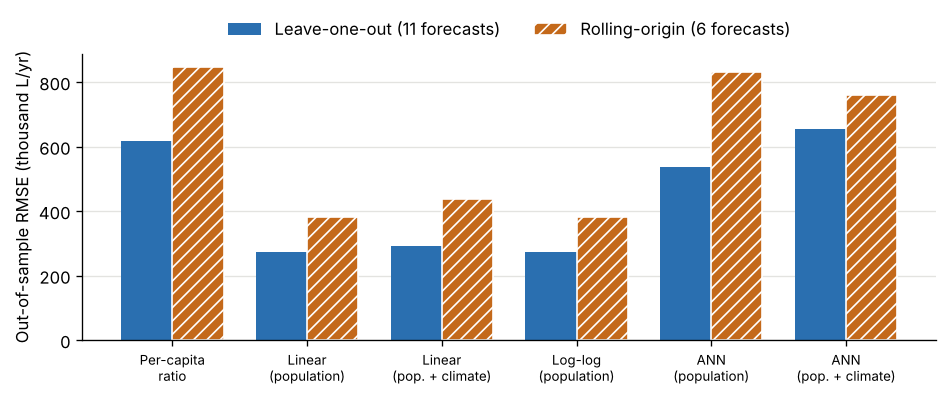

In [6]:
labels = ["Per-capita\nratio", "Linear\n(population)", "Linear\n(pop. + climate)", "Log-log\n(population)", "ANN\n(population)", "ANN\n(pop. + climate)"]
x = np.arange(len(models)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(x - w/2, [loo[m]["RMSE"]/1e3 for m in models], w, color=BLUE, label="Leave-one-out (11 forecasts)")
ax.bar(x + w/2, [ro[m]["RMSE"]/1e3 for m in models], w, color=ORANGE, hatch="///", edgecolor="white", label="Rolling-origin (6 forecasts)")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Out-of-sample RMSE (thousand L/yr)"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.tight_layout(); plt.show()

## 5. Is the ANN just badly set up?

To give the ANN a fair chance, 24 alternative settings are tried for the population-only network: hidden layers of (2), (4), (8) and (4, 4) units, L2 penalties of 0.001, 0.1 and 1, and tanh or ReLU activations. This screen favours the ANN, because the best setting is chosen after seeing the test results.

In [7]:
grid = []
for hidden, alpha, act in itertools.product([(2,), (4,), (8,), (4, 4)], [1e-3, 1e-1, 1.0], ["tanh", "relu"]):
    kw = dict(hidden=hidden, alpha=alpha, activation=act, seeds=15)
    p_loo = np.array([ann_predict(X[np.arange(n) != i][:, :1], dem[np.arange(n) != i], X[i:i+1][:, :1], **kw)[0] for i in range(n)])
    p_ro  = np.array([ann_predict(X[:k][:, :1], dem[:k], X[k:k+1][:, :1], **kw)[0] for k in range(5, n)])
    grid.append((hidden, alpha, act, metrics(dem, p_loo)["RMSE"], metrics(dem[5:], p_ro)["RMSE"]))

best = min(grid, key=lambda g: g[3])
print(f"Median ANN RMSE over 24 settings: LOO {np.median([g[3] for g in grid])/1e3:,.0f} thousand L, RO {np.median([g[4] for g in grid])/1e3:,.0f} thousand L")
print(f"Best setting by LOO: hidden={best[0]}, alpha={best[1]}, {best[2]}  ->  LOO RMSE {best[3]/1e3:,.0f}, RO RMSE {best[4]/1e3:,.0f} thousand L")
print(f"Linear regression on population:  LOO RMSE {loo['Linear (population)']['RMSE']/1e3:,.0f}, RO RMSE {ro['Linear (population)']['RMSE']/1e3:,.0f} thousand L")

Median ANN RMSE over 24 settings: LOO 393 thousand L, RO 600 thousand L
Best setting by LOO: hidden=(8,), alpha=0.1, tanh  ->  LOO RMSE 328, RO RMSE 531 thousand L
Linear regression on population:  LOO RMSE 274, RO RMSE 383 thousand L


## 6. Why a single 80/20 split is not enough

With 11 years, an 80/20 split leaves two test years. The next cell repeats a random 80/20 split 200 times and records the test R² of two models.

In [8]:
rng = np.random.default_rng(1)
split = {"Linear (population)": [], "ANN (population + climate)": []}
for _ in range(200):
    idx = rng.permutation(n); te = np.sort(idx[:2]); tr = np.sort(idx[2:])
    for m in split:
        p = make_model(m)(X[tr], dem[tr], X[te]); y = dem[te]
        split[m].append(1 - np.sum((y - p)**2) / np.sum((y - y.mean())**2))
for m, v in split.items():
    v = np.array(v)
    print(f"{m:<28} median R2 {np.median(v):5.2f}   5th to 95th percentile {np.percentile(v,5):6.1f} to {np.percentile(v,95):5.2f}   negative in {np.mean(v<0)*100:.0f}% of splits")

Linear (population)          median R2  0.87   5th to 95th percentile   -6.9 to  0.99   negative in 16% of splits
ANN (population + climate)   median R2  0.29   5th to 95th percentile  -12.8 to  0.90   negative in 44% of splits


## 7. Projection to 2035

Population is projected from the 2024 value at the observed growth rate (central), at 2.5% and 4.5% per year (low and high), and along a linear trend. Demand comes from linear regression on population, with 95% prediction intervals. Projected populations are well outside the range of the training data, so these are scenarios and not forecasts with guaranteed accuracy.

In [9]:
Apop = np.c_[np.ones(n), pop]
beta = np.linalg.lstsq(Apop, dem, rcond=None)[0]
resid = dem - Apop @ beta
s2 = resid @ resid / (n - 2)
tcrit = stats.t.ppf(0.975, n - 2)
XtXi = np.linalg.inv(Apop.T @ Apop)

def predict_interval(P):
    a = np.array([1.0, P]); mu = a @ beta
    se = np.sqrt(s2 * (1 + a @ XtXi @ a))
    return mu, mu - tcrit * se, mu + tcrit * se

lin_slope = np.polyfit(year, pop, 1)[0]
scen = {"Low growth (2.5% per year)": pop[-1] * 1.025**11,
        "Central (observed 3.5% per year)": pop[-1] * (1 + pop_cagr)**11,
        "High growth (4.5% per year)": pop[-1] * 1.045**11,
        "Linear population trend": pop[-1] + lin_slope * 11}
print(f"Linear model: slope {beta[1]:,.0f} L per extra person per year, in-sample R2 {1 - resid@resid/np.sum((dem-dem.mean())**2):.2f}")
print(f"{'Scenario':<36}{'Pop 2035':>10}{'Demand (million L)':>20}{'95% interval':>20}")
for k, P in scen.items():
    mu, lo, hi = predict_interval(P)
    print(f"{k:<36}{P:>10,.0f}{mu/1e6:>20.1f}{f'{lo/1e6:.1f} to {hi/1e6:.1f}':>20}")

Pc = scen["Central (observed 3.5% per year)"]; Xc = np.array([[Pc, rain.mean(), temp.mean(), hum.mean()]])
print("\nSensitivity to model form at the central population (million L):")
for m in ("Log-log (population)", "Per-capita ratio", "ANN (population)"):
    print(f"  {m:<24}{make_model(m)(X, dem, Xc)[0]/1e6:6.1f}")

Linear model: slope 1,075 L per extra person per year, in-sample R2 0.96
Scenario                              Pop 2035  Demand (million L)        95% interval
Low growth (2.5% per year)              15,475                12.0        10.9 to 13.0
Central (observed 3.5% per year)        17,217                13.8        12.6 to 15.1
High growth (4.5% per year)             19,140                15.9        14.4 to 17.4
Linear population trend                 15,565                12.1        11.0 to 13.1

Sensitivity to model form at the central population (million L):
  Log-log (population)      15.8
  Per-capita ratio          10.4


  ANN (population)           9.6


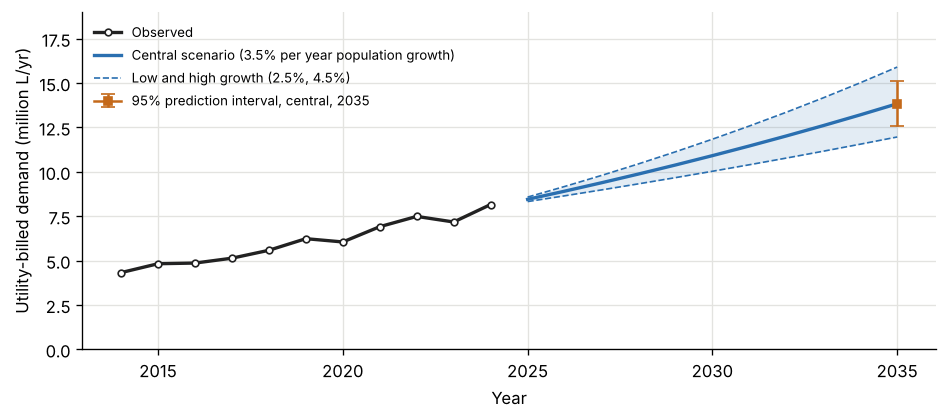

In [10]:
yrs = np.arange(2025, 2036)
def path(g): return beta[0] + beta[1] * pop[-1] * (1 + g)**(yrs - 2024)
mu, lo, hi = predict_interval(Pc)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(year, dem/1e6, color="#222222", lw=2, marker="o", ms=4, mfc="white", label="Observed")
ax.fill_between(yrs, path(0.025)/1e6, path(0.045)/1e6, color=BLUE, alpha=0.13, lw=0)
ax.plot(yrs, path(pop_cagr)/1e6, color=BLUE, lw=2, label="Central scenario (3.5% per year population growth)")
ax.plot(yrs, path(0.025)/1e6, color=BLUE, lw=1, ls="--", label="Low and high growth (2.5%, 4.5%)"); ax.plot(yrs, path(0.045)/1e6, color=BLUE, lw=1, ls="--")
ax.errorbar([2035], [mu/1e6], yerr=[[(mu-lo)/1e6], [(hi-mu)/1e6]], color=ORANGE, capsize=4, marker="s", ms=5, label="95% prediction interval, central, 2035")
ax.set_xlabel("Year"); ax.set_ylabel("Utility-billed demand (million L/yr)"); ax.set_ylim(0, 19)
ax.legend(frameon=False, loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

## 8. Reproducibility check

This cell compares key results with the values reported in the manuscript and stops with an error if any differ by more than rounding.

In [11]:
checks = {
    "Linear (population), LOO RMSE (thousand L)": (loo["Linear (population)"]["RMSE"]/1e3, 274),
    "Linear (population), RO RMSE (thousand L)":  (ro["Linear (population)"]["RMSE"]/1e3, 383),
    "ANN (population), LOO RMSE (thousand L)":    (loo["ANN (population)"]["RMSE"]/1e3, 536),
    "ANN (population), RO RMSE (thousand L)":     (ro["ANN (population)"]["RMSE"]/1e3, 833),
    "Central 2035 demand (million L)":            (predict_interval(Pc)[0]/1e6, 13.8),
    "Population elasticity":                      (b[1], 1.78),
}
ok = True
for k, (got, paper) in checks.items():
    tol = 0.6 if "thousand" in k else 0.06
    good = abs(got - paper) <= tol; ok &= good
    print(f"{'OK ' if good else 'DIFF'}  {k:<46} notebook {got:8.2f}   paper {paper}")
assert ok, "Some results differ from the paper; check package versions."
print("\nAll key results match the manuscript.")

OK   Linear (population), LOO RMSE (thousand L)     notebook   274.49   paper 274
OK   Linear (population), RO RMSE (thousand L)      notebook   382.56   paper 383
OK   ANN (population), LOO RMSE (thousand L)        notebook   535.75   paper 536
OK   ANN (population), RO RMSE (thousand L)         notebook   832.62   paper 833
OK   Central 2035 demand (million L)                notebook    13.83   paper 13.8
OK   Population elasticity                          notebook     1.78   paper 1.78

All key results match the manuscript.
